
# **NeuraSight – `vision-engine-v1.ipynb`**

> **Important:** This notebook **runs** but produces **scientifically unreliable** results.  
> Your task (in a separate exam notebook) is to **diagnose, stabilize, and justify** fixes.

**Known modules in this version:**
- Gaussian smoothing
- Canny edges 
- Harris corners 
- Descriptors 
- Matching 
- RANSAC homography 


## 1) Imports & Setup

In [1]:

import os, math, random, time
from typing import List, Tuple
import numpy as np
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)


OpenCV: 4.14.0
NumPy: 2.5.5



## 2) Data Paths (Use **your own captured images**)
Provide two pairs at minimum (illumination change + viewpoint change).  
Use at least HD resolution (≥ 960×720).


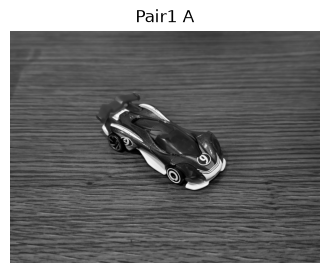

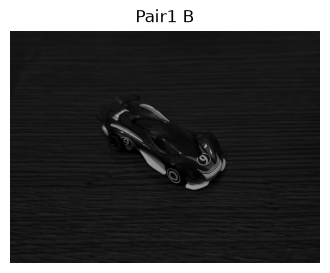

In [2]:

# === Update these paths to your own captures ===
IMG_A_1 = './dataset/pair1_A.jpg'  # illumination / viewpoint variant
IMG_B_1 = './dataset/pair1_B.jpg'
IMG_A_2 = './dataset/pair2_A.jpg'
IMG_B_2 = './dataset/pair2_B.jpg'

def load_gray(path: str) -> np.ndarray:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    assert img is not None, f"Image not found: {path}"
    return img

def show(img, title=None):
    plt.figure(figsize=(4,4))
    if img.ndim == 2:
        plt.imshow(img, cmap='gray')
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    if title: plt.title(title)
    plt.axis('off'); plt.show()

A1 = load_gray(IMG_A_1); B1 = load_gray(IMG_B_1)
show(A1, "Pair1 A"); show(B1, "Pair1 B")



## 3) Gaussian Smoothing

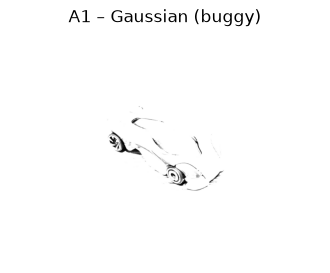

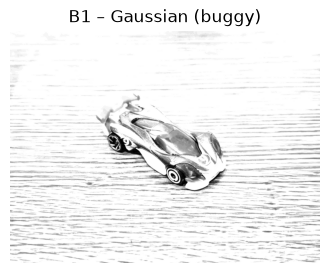

In [3]:

def gaussian_kernel_buggy(size: int, sigma: float) -> np.ndarray:
    ax = np.arange(-(size//2), size//2 + 1)
    xx, yy = np.meshgrid(ax, ax)
    
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma))
    
    return kernel.astype(np.float32)

def convolve(img: np.ndarray, k: np.ndarray) -> np.ndarray:
    return cv2.filter2D(img, -1, k)

A1_smooth = convolve(A1, gaussian_kernel_buggy(7, 2.0))
B1_smooth = convolve(B1, gaussian_kernel_buggy(7, 2.0))
show(A1_smooth, "A1 – Gaussian (buggy)"); show(B1_smooth, "B1 – Gaussian (buggy)")



## 4) Edge Detection (Canny) 

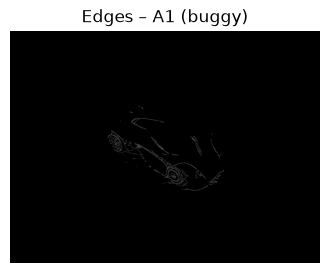

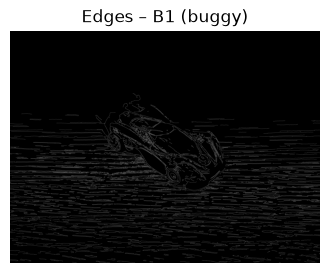

In [4]:

def canny_buggy(img: np.ndarray, low: int=150, high: int=50) -> np.ndarray:
    
    return cv2.Canny(img, threshold1=high, threshold2=low)

E_A1 = canny_buggy(A1_smooth)
E_B1 = canny_buggy(B1_smooth)
show(E_A1, "Edges – A1 (buggy)"); show(E_B1, "Edges – B1 (buggy)")



## 5) Harris Corners 

kpsA: 25 kpsB: 7


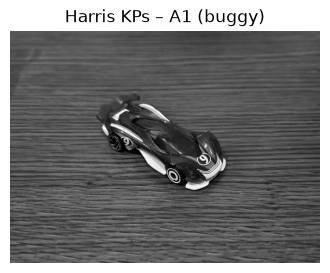

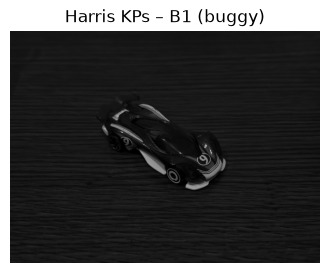

In [5]:

def harris_response_buggy(img: np.ndarray, block=2, ksize=3, k=0.04):
    img32 = np.float32(img)
    R = cv2.cornerHarris(img32, block, ksize, k)
    
    return R

def harris_kps_buggy(R: np.ndarray, thresh: float=1e7) -> List[cv2.KeyPoint]:
    
    ys, xs = np.where(R > thresh)
    return [cv2.KeyPoint(float(x), float(y), 3) for (y, x) in zip(ys, xs)]

R_A1 = harris_response_buggy(A1_smooth)
R_B1 = harris_response_buggy(B1_smooth)
kpsA = harris_kps_buggy(R_A1, thresh=1e7)
kpsB = harris_kps_buggy(R_B1, thresh=1e7)

print("kpsA:", len(kpsA), "kpsB:", len(kpsB))

outA = cv2.drawKeypoints(A1, kpsA, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
outB = cv2.drawKeypoints(B1, kpsB, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show(outA, "Harris KPs – A1 (buggy)"); show(outB, "Harris KPs – B1 (buggy)")



## 6) Descriptors

In [6]:

def extract_patches_buggy(img: np.ndarray, kps: List[cv2.KeyPoint], patch: int=11) -> Tuple[np.ndarray, List[int]]:
    r = patch // 2
    H, W = img.shape[:2]
    descs, keep_idx = [], []
    for i, kp in enumerate(kps):
        x, y = int(round(kp.pt[0])), int(round(kp.pt[1]))
        x0, x1, y0, y1 = x-r, x+r+1, y-r, y+r+1
        if x0 < 0 or y0 < 0 or x1 > W or y1 > H:
            continue  # silently drop near-border KPs
        patch_img = img[y0:y1, x0:x1].astype(np.float32)
        vec = patch_img.flatten()
        
        vec = vec / (vec.max() + 1e-6)
        descs.append(vec)
        keep_idx.append(i)
    if len(descs)==0:
        return np.zeros((0, patch*patch), dtype=np.float32), []
    return np.stack(descs), keep_idx

D_A, idxA = extract_patches_buggy(A1, kpsA, patch=11)
D_B, idxB = extract_patches_buggy(B1, kpsB, patch=11)
print("D_A:", D_A.shape, "D_B:", D_B.shape)


D_A: (25, 121) D_B: (7, 121)



## 7) Matching

In [7]:

def match_ratio_buggy(D1: np.ndarray, D2: np.ndarray, ratio: float=0.6):
    if D1.size==0 or D2.size==0:
        return []
    bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
    knn = bf.knnMatch(D1, D2, k=2)
    good = []
    for m, n in knn:
        if m.distance < ratio * n.distance:
            good.append(m)
    return good

matches = match_ratio_buggy(D_A, D_B, ratio=0.6)
print("matches:", len(matches))


matches: 0



## 8) Homography with RANSAC

H: False inliers: 0 / 0


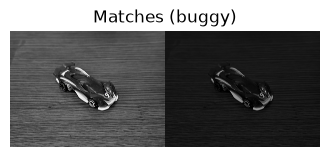

In [8]:

def kp_subset(kps, idxs):
    return [kps[i] for i in idxs]

kpsA_f = kp_subset(kpsA, idxA)
kpsB_f = kp_subset(kpsB, idxB)

def ransac_homography_buggy(kps1, kps2, matches, reproj=1.0, maxIters=100):
    if len(matches) < 4:
        return None, None
    pts1 = np.float32([kps1[m.queryIdx].pt for m in matches]).reshape(-1,1,2)
    pts2 = np.float32([kps2[m.trainIdx].pt for m in matches]).reshape(-1,1,2)
    H, mask = cv2.findHomography(pts1, pts2, cv2.RANSAC, ransacReprojThreshold=reproj, maxIters=maxIters)
    return H, mask

H, mask = ransac_homography_buggy(kpsA_f, kpsB_f, matches, reproj=0.8, maxIters=80)
print("H:", H is not None, "inliers:", int(mask.sum()) if mask is not None else 0, "/", len(matches))

vis_matches = cv2.drawMatches(A1, kpsA_f, B1, kpsB_f, matches, None,
                              matchesMask=(mask.ravel().tolist() if mask is not None else None))
show(vis_matches, "Matches (buggy)")



## 9) Quick Check on Pair 2 (Optional)
Repeat the baseline pipeline on your second pair. Expect **unstable** behavior.


Pair2 — H: False inliers: 0 / 0


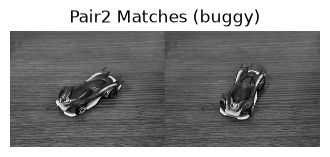

In [9]:

A2 = load_gray(IMG_A_2); B2 = load_gray(IMG_B_2)
A2_s = convolve(A2, gaussian_kernel_buggy(7, 2.0))
B2_s = convolve(B2, gaussian_kernel_buggy(7, 2.0))

E_A2 = canny_buggy(A2_s); E_B2 = canny_buggy(B2_s)
R_A2 = harris_response_buggy(A2_s); R_B2 = harris_response_buggy(B2_s)
kpsA2 = harris_kps_buggy(R_A2, thresh=1e7); kpsB2 = harris_kps_buggy(R_B2, thresh=1e7)

D_A2, idxA2 = extract_patches_buggy(A2, kpsA2, patch=11)
D_B2, idxB2 = extract_patches_buggy(B2, kpsB2, patch=11)
matches2 = match_ratio_buggy(D_A2, D_B2, ratio=0.6)

kpsA2_f = [kpsA2[i] for i in idxA2]
kpsB2_f = [kpsB2[i] for i in idxB2]
H2, mask2 = ransac_homography_buggy(kpsA2_f, kpsB2_f, matches2, reproj=0.8, maxIters=80)

print("Pair2 — H:", H2 is not None, "inliers:", int(mask2.sum()) if mask2 is not None else 0, "/", len(matches2))
vis2 = cv2.drawMatches(A2, kpsA2_f, B2, kpsB2_f, matches2, None,
                       matchesMask=(mask2.ravel().tolist() if mask2 is not None else None))
show(vis2, "Pair2 Matches (buggy)")


> In your **exam notebook**, you will diagnose, fix, and justify improved designs for each module.
